# 16 The 07:00 cutoff: split against combined models (D-005)

Both run times are required. Notebooks 07-15 used the 09:00 cutoff only. What differs at 07:00 (notebook 05 coverage, over the development days):

- **Demand** (`demand_mw`, its age, its anomaly) is available for only 21% of the rows at 07:00, all of them in hours 23 and 00:00-04:00 of the day. For the other rows the demand forecast arrives about 08:48 on D-1. At 09:00 it is available for 99%. So at 07:00 the demand inputs are effectively missing.
- **Wind and embedded wind/solar** are available at both cutoffs (99.5%), but the 09:00 vintage is a later one: 45% (wind) to 94% (embedded wind) of values differ between the two vintages.
- **Revision features** (`*_rev`, the 09:00 value minus the 07:00 value) do not exist at 07:00.
- Price history: `ref28`, `med7_same`, `d2_same`, `level7`, `level28` and the margin columns are identical at both cutoffs (the same prices are known). `level24h` and `level_gap` are not: they use a 24-hour window ending one hour before the cutoff, so they differ slightly between the two.

The model is the best structure so far (notebook 15, section 6, D-008 candidate): `forecast = ref28 + L(D) + centred V0 deviation`, where V0 is the notebook-14 model with absolute weather inputs and history terms (Huber alpha 30 or gradient boosting, on the deviation from `ref28`), centred within each day, and `L(D)` is the daily Huber level model on the daily mean anomalies. The structure is not changed here; only the training set and the inputs are.

Configurations, fixed before running, each for Huber and gradient boosting:

| Config | Trained on | Scored at | Demand inputs |
| --- | --- | --- | --- |
| split 09 | 09:00 rows | 09:00 | yes (replicates 15) |
| split 09, no demand | 09:00 rows | 09:00 | no (what demand adds) |
| split 07 | 07:00 rows | 07:00 | no (revision columns also dropped) |
| combined | 07:00 and 09:00 rows stacked, with a 09:00 indicator | 07:00 and 09:00 | kept; missing at 07:00 (gradient boosting handles missing values natively; for Huber the missing value is replaced by the training median, so at 07:00 the demand terms are constant) |

For the level model the same four settings apply (the combined version stacks the daily rows of both cutoffs and adds the indicator). Each is reported alone (`V0 alone`) and with the anomaly level (`+ level`). Same 17 folds, same scored rows, all folds, folds 0-12 and 13-16. Everything here is dev-only.

## Init

In [1]:
import sys, time
sys.path[:0] = ["notebooks", "."]  # _common imports from repo root or notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import HuberRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler

from _eval import make_folds, score

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 100})

TT = pd.read_parquet("outputs/feature_table_dev.parquet").reset_index(drop=True)
TT["cut9"] = (TT["cutoff_hour"] == 9).astype(float)
REF = "med28_same"
days = pd.DatetimeIndex(sorted(TT["day"].unique()))
folds = make_folds(days, 28, 17, 1)
val_days_all = pd.DatetimeIndex(np.concatenate([f["val_days"].values for f in folds]))
late_days = pd.DatetimeIndex(np.concatenate([folds[k]["val_days"].values for k in range(13, 17)]))
COMMON = TT[REF].notna() & TT["price"].notna()
TT["ydev"] = TT["price"] - TT[REF]
CUT = {7: TT["cutoff_hour"] == 7, 9: TT["cutoff_hour"] == 9}
print(len(TT), "rows;", {c: int((m & COMMON & TT["day"].isin(val_days_all)).sum()) for c, m in CUT.items()}, "scored rows per cutoff")

# price, reference and the slow history columns are identical at the two cutoffs; level24h / level_gap use a window ending 1 h before each cutoff
a = TT[CUT[7]].set_index("period_start"); b = TT[CUT[9]].set_index("period_start")
same = lambda c: bool(np.allclose(a[c].to_numpy(float), b.loc[a.index, c].to_numpy(float), equal_nan=True))
print({c: same(c) for c in ["price", REF, "med7_same", "d2_same", "level7", "level28", "level24h", "level_gap"]})

64702 rows; {7: 22847, 9: 22847} scored rows per cutoff
{'price': True, 'med28_same': True, 'med7_same': True, 'd2_same': True, 'level7': True, 'level28': True, 'level24h': False, 'level_gap': False}


## 1. Models

The feature lists are those of notebook 14, variant V0 (absolute weather plus history). Demand inputs are removed in the `no demand` configurations: `demand_mw` (and its spline), `demand_age_h`, `demand_rev`. At 07:00 the other `*_rev` columns do not exist either, so they are removed in the split 07 configuration.

In [2]:
ABS = ["demand_mw", "wind_mw", "emb_wind_mw", "emb_solar_mw"]
ANOM = ["demand_anom", "wind_anom", "emb_wind_anom", "emb_solar_anom"]
HIST = ["med28_same", "med7_same", "d2_same", "level24h", "level7", "level28", "level_gap"]
MGN = ["mgn_min_demand", "mgn_surplus", "mgn_constrained", "mgn_gen_avail", "mgn_ic_import"]
OTH = ["bank_holiday", "doy_sin", "doy_cos", "clock_change_day"]
GBM_EXTRA = ["wind_total_mw", "demand_age_h", "wind_age_h", "emb_age_h", "demand_rev", "wind_rev", "emb_wind_rev", "emb_solar_rev", "is_weekend"]
DEMAND_COLS = {"demand_mw", "demand_age_h", "demand_rev", "demand_anom"}
REV_COLS = {"demand_rev", "wind_rev", "emb_wind_rev", "emb_solar_rev"}

def v0_model(fam, drop, add_cut):
    """drop: set of columns to remove; add_cut: add the 09:00 indicator."""
    if fam == "huber":
        weather = [c for c in ABS if c not in drop]
        lin = HIST + MGN + OTH + (["cut9"] if add_cut else [])
        parts = []
        if weather:
            parts.append(("spl", make_pipeline(SimpleImputer(strategy="median"), SplineTransformer(n_knots=6, degree=3, extrapolation="linear"), StandardScaler()), weather))
        parts += [("hour", SplineTransformer(knots=np.linspace(0, 24, 13).reshape(-1, 1), degree=3, extrapolation="periodic"), ["hour_frac"]),
                  ("lin", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), lin),
                  ("wd", OneHotEncoder(handle_unknown="ignore"), ["weekday"])]
        cols = weather + ["hour_frac"] + lin + ["weekday"]
        return Pipeline([("pre", ColumnTransformer(parts)), ("est", HuberRegressor(alpha=30, epsilon=1.35, max_iter=300))]), cols
    cols = ["hour_frac", "weekday", "bank_holiday", "doy_sin", "doy_cos", "clock_change_day"] + ABS + MGN + GBM_EXTRA + HIST
    if add_cut:
        cols.append("cut9")
    cols = [c for c in dict.fromkeys(cols) if c not in drop]
    m = HistGradientBoostingRegressor(loss="absolute_error", max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                      min_samples_leaf=100, l2_regularization=1.0, early_stopping=False, random_state=0)
    return m, cols

# daily table for the level part, one per cutoff (the target is the same at both: it uses prices and ref28 only)
dm = TT[COMMON & CUT[9]].groupby("day")["ydev"].agg(["mean", "count"])
DAILY = {}
for c in (7, 9):
    g = TT[CUT[c]].groupby("day")
    d = g[ANOM].mean()
    d["is_weekend"] = g["is_weekend"].mean(); d["bank_holiday"] = g["bank_holiday"].mean()
    d["target"] = dm["mean"].where(dm["count"] >= 40).reindex(d.index)
    d["cut9"] = float(c == 9)
    DAILY[c] = d
print({c: d["demand_anom"].notna().mean().round(2) for c, d in DAILY.items()}, "share of days with a daily demand anomaly (07, 09)")
print({c: d[ANOM].notna().mean().round(2).to_dict() for c, d in DAILY.items()})

def level_model():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), HuberRegressor(alpha=10, epsilon=1.35, max_iter=300))

def fold_table(pred, cut):
    rows = []
    for f in folds:
        d = TT[CUT[cut] & COMMON & TT["day"].isin(f["val_days"])].assign(pred=pred)
        s = score(d, "pred"); s["fold"] = f["fold"]; rows.append(s)
    return pd.DataFrame(rows).set_index("fold")

BASE = {c: fold_table(TT[REF], c) for c in (7, 9)}
print("baseline MAE by cutoff:", {c: round(BASE[c]["MAE"].mean(), 3) for c in BASE}, "(should be equal: same reference, same rows)")

{7: np.float64(0.97), 9: np.float64(0.97)} share of days with a daily demand anomaly (07, 09)
{7: {'demand_anom': 0.97, 'wind_anom': 0.97, 'emb_wind_anom': 0.97, 'emb_solar_anom': 0.97}, 9: {'demand_anom': 0.97, 'wind_anom': 0.97, 'emb_wind_anom': 0.97, 'emb_solar_anom': 0.97}}


baseline MAE by cutoff: {7: np.float64(30.203), 9: np.float64(30.203)} (should be equal: same reference, same rows)


## 2. Run

One function fits the V0 model and the level model for each fold on the stated training rows and predicts the stated cutoffs. `forecast = ref28 + level + centred V0 deviation` (as in 15, section 6), where the centring is within each day on the scored cutoff's rows.

In [3]:
def run(fam, train_cuts, eval_cuts, drop, level_demand):
    add_cut = len(train_cuts) > 1
    dev0 = {c: pd.Series(np.nan, index=TT.index) for c in eval_cuts}
    lvl = {c: pd.Series(np.nan, index=DAILY[c].index) for c in eval_cuts}
    ldrop = set() if level_demand else {"demand_anom"}
    lcols = [c for c in ANOM + ["is_weekend", "bank_holiday"] if c not in ldrop] + (["cut9"] if add_cut else [])
    for f in folds:
        tr = TT[TT["cutoff_hour"].isin(train_cuts) & TT["day"].isin(f["train_days"]) & COMMON]
        m, cols = v0_model(fam, drop, add_cut)
        m.fit(tr[cols], tr["ydev"])
        dtr = pd.concat([DAILY[c].loc[DAILY[c].index.isin(f["train_days"])] for c in train_cuts])
        dtr = dtr[dtr["target"].notna()]
        lm = level_model().fit(dtr[lcols], dtr["target"])
        for c in eval_cuts:
            va = TT[CUT[c] & TT["day"].isin(f["val_days"])]
            dev0[c].loc[va.index] = m.predict(va[cols])
            dva = DAILY[c].loc[DAILY[c].index.isin(f["val_days"])]
            lvl[c].loc[dva.index] = lm.predict(dva[lcols])
    out = {}
    for c in eval_cuts:
        d0 = dev0[c]
        d0c = d0 - d0.groupby(TT["day"]).transform("mean")
        out[c] = {"V0 alone": TT[REF] + d0, "+ level": TT[REF] + TT["day"].map(lvl[c]) + d0c}
        out[c] = {k: v.where(CUT[c]) for k, v in out[c].items()}
    return out

NODEM = DEMAND_COLS
CONFIGS = {   # name -> (train cuts, eval cuts, dropped columns, level uses demand)
    "split 09":             ([9], [9], set(), True),
    "split 09, no demand":  ([9], [9], NODEM, False),
    "split 07":             ([7], [7], NODEM | REV_COLS, False),
    "combined":             ([7, 9], [7, 9], set(), True),
}
PRED, FT = {}, {}
t0 = time.time()
for fam in ["huber", "gbm"]:
    for name, (tc, ec, drop, ld) in CONFIGS.items():
        out = run(fam, tc, ec, drop, ld)
        for c in ec:
            for variant, p in out[c].items():
                key = (fam, name, c, variant)
                PRED[key] = p; FT[key] = fold_table(p, c)
        print(f"{fam:6s} {name:22s} {time.time() - t0:5.0f}s")

huber  split 09                   8s


huber  split 09, no demand       15s


huber  split 07                  22s


huber  combined                  40s


gbm    split 09                  54s


gbm    split 09, no demand       68s


gbm    split 07                  81s


gbm    combined                 101s


## 3. Replication check

Split 09 should reproduce notebooks 14 and 15: V0 alone against the saved V0 predictions, and `+ level` against the saved recombination metrics (Huber MAE -2.06, hit +0.032/+0.049; GBM MAE -2.04, hit +0.023/+0.040 against the baseline).

In [4]:
old = pd.read_parquet("outputs/cv_preds_anomaly_0900.parquet")
for fam in ["huber", "gbm"]:
    mine = TT.loc[CUT[9], ["period_start"]].assign(p=PRED[(fam, "split 09", 9, "V0 alone")][CUT[9]].values)
    mm = old[["period_start", f"{fam} V0 absolute + history"]].merge(mine, on="period_start")
    print(fam, "V0 alone vs notebook 14, max abs difference:", float((mm[f"{fam} V0 absolute + history"] - mm["p"]).abs().max()))

huber V0 alone vs notebook 14, max abs difference: 0.0
gbm V0 alone vs notebook 14, max abs difference: 0.0


## 4. All configurations

Differences to the 28-day median baseline at the same cutoff (negative is better for MAE and RMSE; positive for hit rates), all folds, folds 0-12 and late folds 13-16. `bias late` and `bias f16` are mean errors (forecast minus actual).

In [5]:
def row(key):
    fam, name, c, variant = key
    ft = FT[key]; b = BASE[c]
    d = {m: ft[m] - b[m] for m in ["MAE", "RMSE", "hit_top8", "hit_bot8", "MAE_top10", "MAE_bot10"]}
    return {"MAE": ft["MAE"].mean(), "dMAE all": d["MAE"].mean(), "dMAE 0-12": d["MAE"].loc[:12].mean(), "dMAE late": d["MAE"].loc[13:].mean(),
            "dRMSE all": d["RMSE"].mean(), "dRMSE late": d["RMSE"].loc[13:].mean(),
            "dHitTop": d["hit_top8"].mean(), "dHitBot": d["hit_bot8"].mean(),
            "dTop10": d["MAE_top10"].mean(), "dBot10": d["MAE_bot10"].mean(),
            "bias late": ft["bias"].loc[13:].mean(), "bias f16": ft["bias"].loc[16]}
R = pd.DataFrame({" | ".join(map(str, k)): row(k) for k in FT}).T
for fam in ["huber", "gbm"]:
    print(fam)
    print(R[R.index.str.startswith(fam)].round(3).to_string()); print()
print("baseline hit rates (07, 09):", {c: (round(BASE[c]["hit_top8"].mean(), 3), round(BASE[c]["hit_bot8"].mean(), 3)) for c in BASE})

huber
                                               MAE  dMAE all  dMAE 0-12  dMAE late  dRMSE all  dRMSE late  dHitTop  dHitBot  dTop10  dBot10  bias late  bias f16
huber | split 09 | 9 | V0 alone             28.298    -1.905     -2.418     -0.235     -4.123      -1.820    0.032    0.049  -2.534 -27.214    -11.773   -15.352
huber | split 09 | 9 | + level              28.140    -2.063     -2.236     -1.501     -4.304      -3.292    0.032    0.049  -4.109 -19.888     -2.185    -8.442
huber | split 09, no demand | 9 | V0 alone  28.912    -1.290     -1.684     -0.010     -3.395      -1.424    0.011    0.018  -0.816 -22.756    -10.606   -13.056
huber | split 09, no demand | 9 | + level   28.663    -1.539     -1.626     -1.259     -3.409      -2.673    0.011    0.018  -2.108 -15.490     -1.565    -6.596
huber | split 07 | 7 | V0 alone             28.902    -1.300     -1.694     -0.021     -3.405      -1.457    0.011    0.018  -0.705 -22.667    -10.683   -13.404
huber | split 07 | 7 | + lev

## 5. Paired comparisons (variant `+ level`)

Mean per-fold difference +/- standard error over the 17 folds (the folds are adjacent, so these standard errors are optimistic); `late` is the mean over folds 13-16. Four questions:

1. What does 07:00 cost? split 07 against split 09 (each scored at its own cutoff).
2. What does demand add at 09:00? split 09 against split 09 without demand.
3. Does a 07:00 forecast gain from the extra 09:00 training rows? combined at 07:00 against split 07.
4. The same at 09:00: combined at 09:00 against split 09.

In [6]:
def paired(a, b):
    r = {}
    for m in ["MAE", "RMSE", "hit_top8", "hit_bot8"]:
        d = FT[a][m] - FT[b][m]
        r[f"{m} all"] = f"{d.mean():+.3f} +/- {d.std() / np.sqrt(17):.3f}"; r[f"{m} late"] = f"{d.loc[13:].mean():+.3f}"
    r["folds MAE better"] = int(((FT[a]["MAE"] - FT[b]["MAE"]) < 0).sum())
    return r
rows = {}
for fam in ["huber", "gbm"]:
    V = "+ level"
    rows[f"{fam}: split 07 - split 09"] = paired((fam, "split 07", 7, V), (fam, "split 09", 9, V))
    rows[f"{fam}: split 09 - split 09 no demand"] = paired((fam, "split 09", 9, V), (fam, "split 09, no demand", 9, V))
    rows[f"{fam}: combined@07 - split 07"] = paired((fam, "combined", 7, V), (fam, "split 07", 7, V))
    rows[f"{fam}: combined@09 - split 09"] = paired((fam, "combined", 9, V), (fam, "split 09", 9, V))
print("(first column named in each row minus the second; MAE/RMSE: negative means the first is better; hit rates: positive)")
print(pd.DataFrame(rows).T.to_string())

(first column named in each row minus the second; MAE/RMSE: negative means the first is better; hit rates: positive)
                                               MAE all MAE late          RMSE all RMSE late      hit_top8 all hit_top8 late      hit_bot8 all hit_bot8 late folds MAE better
huber: split 07 - split 09            +0.512 +/- 0.124   +0.224  +0.891 +/- 0.181    +0.582  -0.022 +/- 0.006        +0.001  -0.030 +/- 0.010        -0.022                2
huber: split 09 - split 09 no demand  -0.523 +/- 0.123   -0.242  -0.895 +/- 0.184    -0.618  +0.022 +/- 0.006        -0.002  +0.031 +/- 0.010        +0.025               15
huber: combined@07 - split 07         -0.088 +/- 0.130   +0.456  -0.257 +/- 0.180    +0.506  +0.005 +/- 0.003        -0.004  -0.015 +/- 0.009        -0.019                9
huber: combined@09 - split 09         +0.110 +/- 0.113   -0.227  +0.066 +/- 0.121    -0.311  -0.003 +/- 0.004        +0.011  -0.015 +/- 0.006        +0.002                7
gbm: split 07 - sp

## 6. Do the two cutoffs give different forecasts?

On the rows both are scored on, the mean absolute difference between the 07:00 and 09:00 forecasts, and how the two correlate in the deviation from the baseline, for the split and combined `+ level` models. A small difference means the 07:00 forecast is nearly the 09:00 one.

In [7]:
rows = {}
for fam in ["huber", "gbm"]:
    for name in ["split 07 / split 09", "combined"]:
        k7, k9 = ((fam, "split 07", 7, "+ level"), (fam, "split 09", 9, "+ level")) if name.startswith("split") else ((fam, "combined", 7, "+ level"), (fam, "combined", 9, "+ level"))
        p7 = PRED[k7][CUT[7]].reset_index(drop=True); p9 = PRED[k9][CUT[9]].reset_index(drop=True)
        t = pd.DataFrame({"p7": p7.values, "p9": p9.values, "ref": TT.loc[CUT[9], REF].values, "day": TT.loc[CUT[9], "day"].values})
        t = t[t["day"].isin(val_days_all)].dropna()
        rows[f"{fam}: {name}"] = {"rows": len(t), "mean |p07 - p09|": (t["p7"] - t["p9"]).abs().mean(),
                                  "corr of deviations": (t["p7"] - t["ref"]).corr(t["p9"] - t["ref"])}
print(pd.DataFrame(rows).T.round(3).to_string())
P = pd.DataFrame({" | ".join(map(str, k)): v for k, v in PRED.items() if k[3] == "+ level"})
for c in ["day", "period_start", "cutoff_hour", "price", REF]:
    P[c] = TT[c]
P[P["day"].isin(val_days_all)].to_parquet("outputs/cv_preds_cutoffs_0700_0900.parquet", index=False)

                               rows  mean |p07 - p09|  corr of deviations
huber: split 07 / split 09  22847.0             5.845               0.890
huber: combined             22847.0             5.355               0.910
gbm: split 07 / split 09    22847.0             6.114               0.893
gbm: combined               22847.0             4.361               0.953


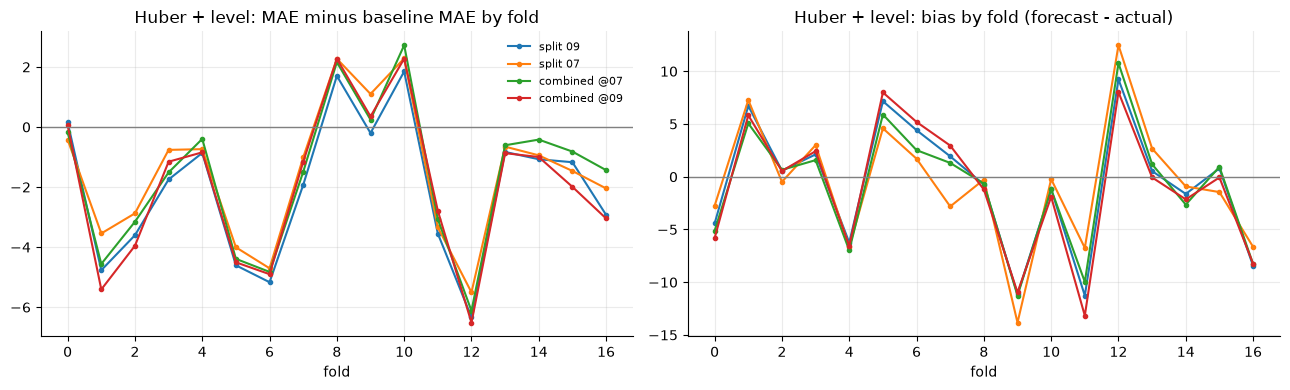

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for key, lab in [(("huber", "split 09", 9, "+ level"), "split 09"), (("huber", "split 07", 7, "+ level"), "split 07"),
                 (("huber", "combined", 7, "+ level"), "combined @07"), (("huber", "combined", 9, "+ level"), "combined @09")]:
    axes[0].plot(FT[key]["MAE"] - BASE[key[2]]["MAE"], marker="o", ms=3, label=lab)
    axes[1].plot(FT[key]["bias"], marker="o", ms=3, label=lab)
axes[0].axhline(0, color="grey", lw=1); axes[1].axhline(0, color="grey", lw=1)
axes[0].set_title("Huber + level: MAE minus baseline MAE by fold"); axes[1].set_title("Huber + level: bias by fold (forecast - actual)")
axes[0].legend(frameon=False, fontsize=8)
for ax in axes: ax.set_xlabel("fold")
plt.tight_layout(); plt.show()

## Findings (17 folds, structure of notebook 15 section 6; the configurations were specified before running; differences are to the 28-day median baseline at the same cutoff, which is identical at 07:00 and 09:00: MAE 30.2, hit 0.462/0.322)

- **Replication holds.** Split 09 V0 predictions match notebook 14 exactly (max difference 0.0), and `+ level` reproduces notebook 15 (Huber MAE -2.06, hit +0.032/+0.049; GBM MAE -2.04, +0.023/+0.040).
- **Almost all of the difference between 07:00 and 09:00 is the demand forecast.** Split 07 and split 09 without demand are nearly identical (Huber `+ level` MAE -1.55 against -1.54, GBM -1.70 against -1.79), so the later 09:00 wind and solar vintages add nothing measurable. Adding demand at 09:00 improves Huber by MAE -0.52 +/- 0.12 (15 of 17 folds), RMSE -0.90, hit +0.022/+0.031 (all paired); for GBM MAE -0.26 +/- 0.13 and the hit rates barely move (+0.002/+0.010).
- **What 07:00 costs.** Split 07 against split 09: Huber MAE +0.51 +/- 0.12, RMSE +0.89, hit -0.022/-0.030, i.e. most of Huber's ranking gain is lost (07:00 Huber hit gain over the baseline +0.011/+0.018 against +0.032/+0.049). GBM loses less in ranking: MAE +0.35 +/- 0.12, hit -0.005/-0.011, so at 07:00 GBM is the better family (MAE -1.70, hit +0.018/+0.028 over the baseline; Huber MAE -1.55, hit +0.011/+0.018). The 07:00 models still beat the baseline on MAE and RMSE; their ranking gain over the baseline is small.
- **The level part still works at 07:00 without demand.** Its inputs are then the wind, embedded wind and solar anomalies and the two calendar flags. Late-fold (13-16) MAE gain over the baseline is -1.28 (Huber) and -1.07 (GBM), against -1.50 and -1.61 at 09:00 with demand, and the late mean error is -1.6 (fold 16: -6.6), compared with -2.2 (fold 16: -8.4) at 09:00. The late-fold level problem seen in notebooks 10-14 is corrected here by the same mechanism.
- **Combined against split: no clear difference.** Combined at 07:00 against split 07: MAE -0.09 +/- 0.13 (Huber), -0.18 +/- 0.11 (GBM); combined at 09:00 against split 09: +0.11 +/- 0.11 and +0.12 +/- 0.10 (slightly worse, within the standard error); in the late folds the combined models are mixed (07:00: +0.46 worse and +0.03; 09:00: -0.23 better and +0.15 worse). The hit-rate differences are small, with one exception: Huber combined at 09:00 is worse on bottom-8, -0.015 +/- 0.006. The combined models make the two forecasts closer: mean absolute 07:00-09:00 difference 5.4 (Huber) and 4.4 (GBM) against 5.8 and 6.1 for the split models, correlation of the deviations 0.91/0.95 against 0.89/0.89.
- **Tail columns.** The decile MAE differences are in section 4 (`dTop10`, `dBot10`). Adding the level part improves the top-decile MAE (e.g. Huber split 09: -2.5 to -4.1) and gives back part of the bottom-decile gain of V0 alone (-27 to -20). The bottom-decile gain of the learned models over the baseline is large in every configuration. Read these together with MAE, since decile MAE can be improved by forecasting extremes.
- **Reading.** There is no evidence that stacking the two cutoffs' rows helps, and separate models are simpler and score the same (and Huber split 09 keeps its bottom-8 hit rate). The evidence supports a split design, with the 09:00 model using demand and the 07:00 model not. Family choice may differ by cutoff: Huber at 09:00 for ranking, GBM at 07:00; averaging the two families is untested.
- **Caveats.** (1) The recombination structure was designed on these folds (notebook 15 caveat), and the 07:00 variants were fixed in advance but share the same folds. (2) Standard errors treat the 17 adjacent folds as independent, so they are optimistic; late-fold statements rest on four folds. (3) The GBM settings are deterministic (seeds make no difference, notebooks 09 and 18), so seed noise is not a concern; the fold-to-fold standard errors are the relevant uncertainty. (4) In the combined Huber model the missing 07:00 demand is replaced by the training median, so the demand terms act only through the 09:00 rows; this is one specific way to handle it. (5) `level24h` and `level_gap` differ slightly between the cutoffs by construction (1 h before each cutoff). (6) Quantile and tail-specific models are still not done.
